# **1 Sampling via Inverse Transform Technique**

In [ ]:
# importing necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

In [ ]:
# setting seed value
np.random.seed(100)

In [ ]:
# generating uniform samples
N_total = 1000
array_samples_uniform = np.random.rand(N_total)

In [ ]:
# creating function to implementing the inversed cdf function F inverse
def inverse_cdf(u):
  u = np.asarray(u) # ensuring the u to be an numpy array
  x = np.zeros_like(u, dtype = float)

  tol = 1e-9 # tolerance for floating point comparisons

  # cond 1: u in [0, 1/3) -> x = sqrt(3u) giving x in [0, 1)
  cond1 = (u >= 0) & (u < 1/3 - tol)
  x[cond1] = np.sqrt(3 * u[cond1])

  # Cond 2: u is approximately 1/3 -> x = 1
  cond2 = np.isclose(u, 1/3, atol=tol)
  x[cond2] = 1.0

  # Cond 3: u in (1/3, 2/3) -> x = 2
  # Smallest x where F(x) >= u (when u > 1/3) is x=2, since F(x)=1/3 for 1<=x<2
  cond3 = (u > 1/3 + tol) & (u < 2/3 - tol)
  x[cond3] = 2.0

  # Cond 4: u in [2/3, 1) -> x = 6u - 2 giving x in [2, 4)
  cond4 = (u >= 2/3 - tol) & (u < 1.0 - tol)
  x[cond4] = 6 * u[cond4] - 2

  # Cond 5: u is approximately 1 -> x = 4
  cond5 = np.isclose(u, 1.0, atol=tol)
  x[cond5] = 4.0

  # returning a scaler if input was a scalar
  if u.ndim == 0:
    return x.item()
  return x

In [ ]:
# testing inverse CDF function implementation
print("Testing inverse_cdf(0.1):", inverse_cdf(0.1)) # should be approx 0.5477
print("Testing inverse_cdf(0.333):", inverse_cdf(0.333)) # should be 1.0
print("Testing inverse_cdf(0.5):", inverse_cdf(0.5)) # should be 1.0
print("Testing inverse_cdf(0.7):", inverse_cdf(0.7)) # should be approx 2.2
print("Testing inverse_cdf(1.0):", inverse_cdf(1.0)) # should be 4.0

Testing inverse_cdf(0.1): 0.5477225575051662
Testing inverse_cdf(0.333): 0.999499874937461
Testing inverse_cdf(0.5): 2.0
Testing inverse_cdf(0.7): 2.1999999999999993
Testing inverse_cdf(1.0): 4.0


In [ ]:
# transforming the uniform samples
array_samples_custom = inverse_cdf(array_samples_uniform)

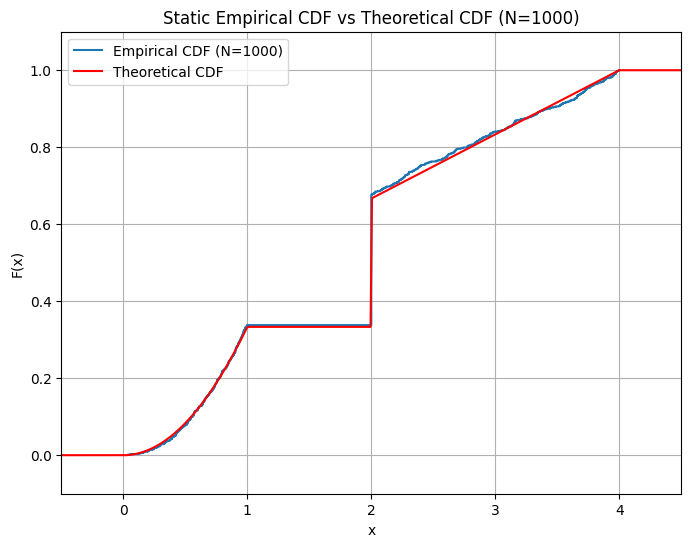

In [ ]:
# carrying the visualizations

# plotting the empirical CDF (static example using all N = 1000 samples)
plt.figure(figsize = (8, 6))
n_all = len(array_samples_custom)
x_sorted_all = np.sort(array_samples_custom)
y_ecdf_all = np.arange(1, n_all + 1) / n_all
plt.plot(x_sorted_all, y_ecdf_all, drawstyle = 'steps-post', label = f'Empirical CDF (N={n_all})')

# adding the theoretical CDF to this static plot for comparison
def theoretical_cdf(x):
    x = np.asarray(x)
    y = np.zeros_like(x, dtype=float)

    cond1 = (x >= 0) & (x < 1)
    y[cond1] = x[cond1]**2 / 3

    cond2 = (x >= 1) & (x < 2)
    y[cond2] = 1/3

    cond3 = (x >= 2) & (x < 4)
    y[cond3] = (x[cond3] + 2) / 6

    cond4 = (x >= 4)
    y[cond4] = 1.0

    if x.ndim == 0:
        return y.item()
    return y

x_theory = np.linspace(-1, 5, 500)
y_theory = theoretical_cdf(x_theory)
plt.plot(x_theory, y_theory, 'r-', label='Theoretica l CDF')

plt.title('Static Empirical CDF vs Theoretical CDF (N=1000)')
plt.xlabel('x')
plt.ylabel('F(x)')
plt.grid(True)
plt.legend()
plt.xlim(-0.5, 4.5)
plt.ylim(-0.1, 1.1)
plt.show()

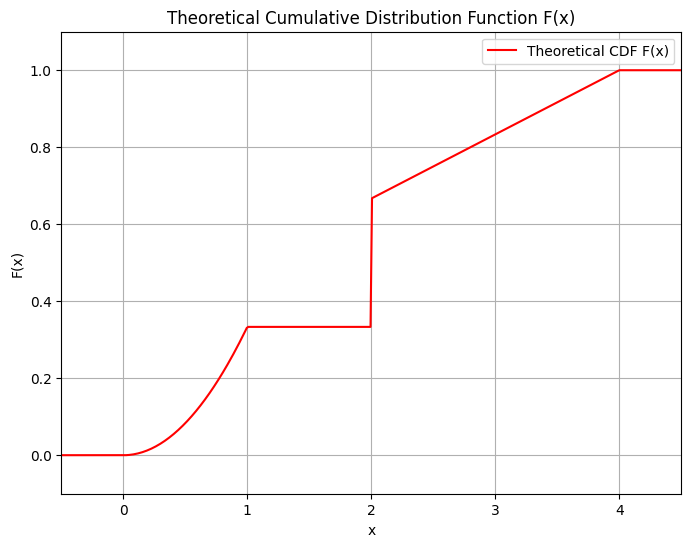

In [ ]:
# plotting theoretical CDF (seperate figure window)
plt.figure(figsize=(8, 6))
plt.plot(x_theory, y_theory, 'r-', label='Theoretical CDF F(x)')
plt.title('Theoretical Cumulative Distribution Function F(x)')
plt.xlabel('x')
plt.ylabel('F(x)')
plt.grid(True)
plt.legend()
plt.xlim(-0.5, 4.5)
plt.ylim(-0.1, 1.1)
plt.show()

In [ ]:
# creaiting animation plot of empirical CDF
fig_anim, ax_anim = plt.subplots(figsize=(8, 6))

# plotting the static theoretical CDF on the animation axes
ax_anim.plot(x_theory, y_theory, 'r-', label='True Hybrid CDF')

# initializing the empirical CDF line (empty at first)
empirical_line, = ax_anim.plot([], [], 'b-', drawstyle='steps-post', label='Empirical CDF')

# setting the plot limits and labels for the animation
ax_anim.set_xlim(-0.5, 4.5)
ax_anim.set_ylim(-0.1, 1.1)
ax_anim.set_xlabel('x')
ax_anim.set_ylabel('CDF Value')
ax_anim.grid(True)
anim_title = ax_anim.set_title('Empirical vs True CDF (n=0)')
ax_anim.legend()

# defining the number of frames and corresponding N values for the animation
N_start = 10
N_end = N_total
num_frames = 100
N_values = np.linspace(N_start, N_end, num_frames, dtype=int)
# ensuring that N_values are unique and increasing
N_values = np.unique(N_values)
if N_values[0] < N_start: N_values = N_values[1:] # ensuring start >= 10
if N_values[-1] < N_end: N_values = np.append(N_values, N_end) # ensuring end = 1000

# update function for the animation
def update(frame_index):
    N_current = N_values[frame_index]

    subset_indices = np.random.choice(N_total, N_current, replace=False)
    uniform_subset = array_samples_uniform[subset_indices]

    # transforming the subset
    custom_subset = inverse_cdf(uniform_subset)

    # calculating empirical CDF for the subset
    x_ecdf = np.sort(custom_subset)
    y_ecdf = np.arange(1, N_current + 1) / N_current

    # preparing data for step plot (ensuring it starts from y=0)
    if N_current > 0:
         x_plot = np.concatenate( ([x_ecdf[0]-1e-9], x_ecdf) )
         y_plot = np.concatenate( ([0.0], y_ecdf) )
         empirical_line.set_data(x_plot, y_plot)
    else:
         empirical_line.set_data([], [])


    # update title
    anim_title.set_text(f'Empirical vs True CDF (n={N_current})')

    return empirical_line, anim_title

ani = animation.FuncAnimation(fig_anim, update, frames=len(N_values),interval=100, blit=False, repeat=False)

html_video = ani.to_html5_video()

plt.close(fig_anim)

display(HTML(html_video))

# **2 Wordle: A Game in Probability**

In [ ]:
# importing the necessary libraries
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.notebook import tqdm
import cvxpy as cp

**Dataset loading, Data Exploration and Setup**

In [ ]:
# data exploration and setup
dataset_path = '/content/wordlist.csv'

try:
    word_df = pd.read_csv(dataset_path, header=None, names=['word'])
    word_list = word_df['word'].tolist()

    total_words = len(word_list)
    print(f"Total number of words loaded: {total_words}")

except FileNotFoundError:
    print(f"Error: Could not find the dataset file at {DATASET_PATH}")
    exit()
except Exception as e:
    print(f"An error occurred while loading the file: {e}")
    exit()

Total number of words loaded: 3103


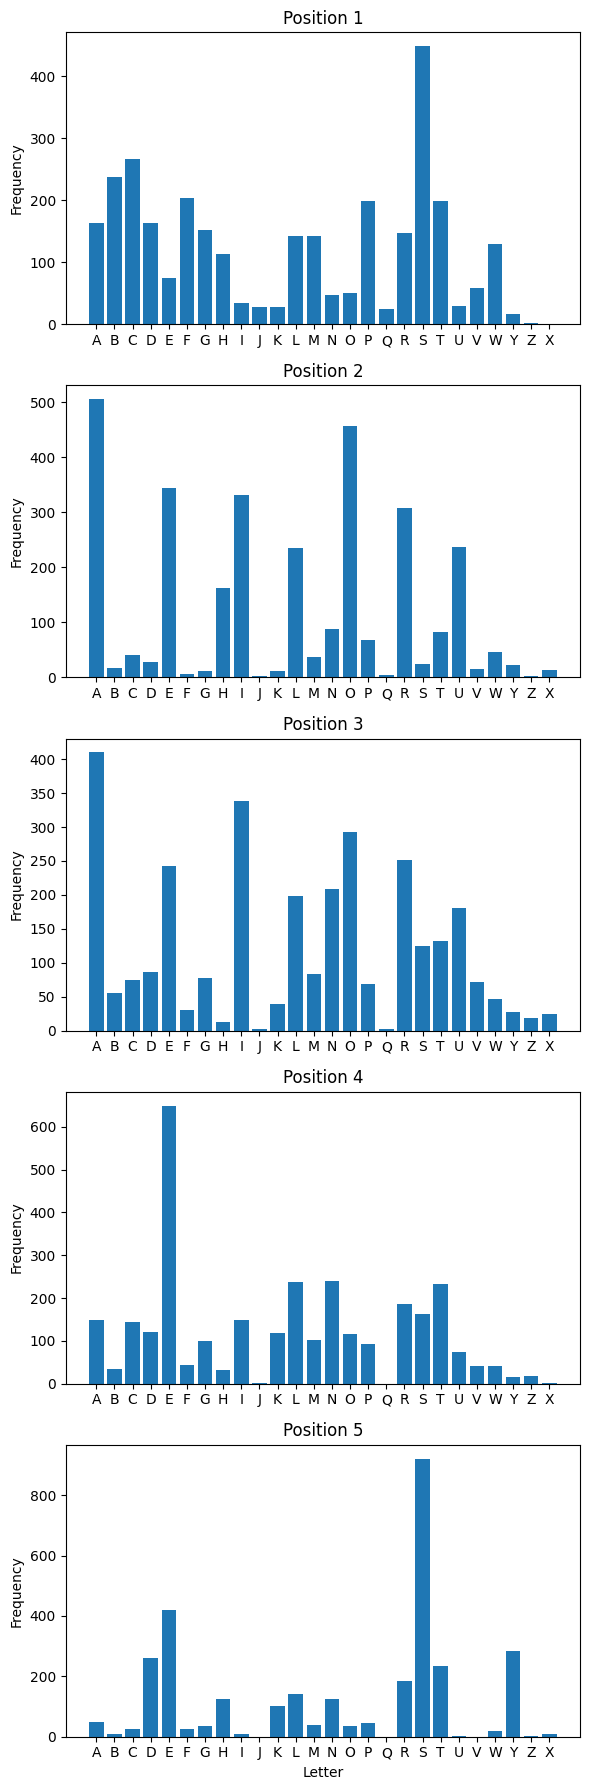

In [ ]:
# computing and visualize the histogram of letters appearing in each position (1 to 5)

fig, axes = plt.subplots(5, 1, figsize=(6, 18), sharex=True)

for i in range(5):
    # extracting letters at the current position
    position_letters = [word[i] for word in word_list]

    # computing letter frequencies for this position
    letter_counts = Counter(position_letters)

    # preparing data for plotting (sorted letters and their counts)
    sorted_letters = sorted(letter_counts.keys())
    counts = [letter_counts[letter] for letter in sorted_letters]

    # creating bar plot on the i-th subplot (axes[i] still works)
    axes[i].bar(sorted_letters, counts)
    axes[i].set_title(f'Position {i+1}')
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='x', labelbottom=True)

    if i == 4:
        axes[i].set_xlabel('Letter')

plt.tight_layout()

plt.show()

**Simulating Wordle Feedback**

In [ ]:
# creating wordle_feedback function
def wordle_feedback(solution, guess):
    green_count = 0
    yellow_count = 0
    sol_list = list(solution)
    guess_list = list(guess)
    sol_check = list(solution)
    guess_check = list(guess)

    # first pass: identifying Green tiles
    for i in range(5):
        if guess_list[i] == sol_list[i]:
            green_count += 1
            sol_check[i] = None
            guess_check[i] = None

    # second pass: identifying Yellow tiles
    for i in range(5):
        if guess_check[i] is not None:
            if guess_check[i] in sol_check:
                yellow_count += 1
                sol_check[sol_check.index(guess_check[i])] = None

    # calculating Gray tiles
    gray_count = 5 - green_count - yellow_count

    return green_count, yellow_count, gray_count


In [ ]:
# demonstrating the function with the specified examples
guess1 = "CRANE"
solution1 = "SLATE"
feedback1 = wordle_feedback(solution1, guess1)
print(f"Guess: {guess1}, Solution: {solution1} ===> Feedback (G, Y, Gr): {feedback1}")

guess2 = "BRAIN"
solution2 = "BRINE"
feedback2 = wordle_feedback(solution2, guess2)
print(f"Guess: {guess2}, Solution: {solution2} ===> Feedback (G, Y, Gr): {feedback2}")

Guess: CRANE, Solution: SLATE ===> Feedback (G, Y, Gr): (2, 0, 3)
Guess: BRAIN, Solution: BRINE ===> Feedback (G, Y, Gr): (2, 2, 1)


In [ ]:
# setting the seed value for reproducibility
SEED = 42
random.seed(SEED)

**Probability Estimation via Averages**

In [ ]:
# probability estimation via averages
N_TRIALS = 1000
GUESS_WORD_CRANE = "CRANE"

# initializing counters for the two estimations
at_least_one_green_count = 0
exactly_two_yellow_count = 0

# checking if word_list exists before proceeding
if 'word_list' not in globals() or not word_list:
    print("Error: 'word_list' not found or empty.")
else:
    # creating the simulation loop
    for _ in range(N_TRIALS):
        # randomly selecting a solution word from the loaded list
        random_solution = random.choice(word_list)

        try:
            g, y, gr = wordle_feedback(random_solution, GUESS_WORD_CRANE)
        except NameError:
            print("Error: 'wordle_feedback' function not defined.")
            exit()

        if g >= 1:
            at_least_one_green_count += 1

        if y == 2:
            exactly_two_yellow_count += 1

    # calculating final probability estimates by averaging the 1/0 results (i.e., dividing count by N_TRIALS)
    prob_at_least_one_green = at_least_one_green_count / N_TRIALS
    prob_exactly_two_yellow = exactly_two_yellow_count / N_TRIALS

    # providing the estimates as required
    print(f"1. Estimated P(at least one green tile | guess={GUESS_WORD_CRANE})  {prob_at_least_one_green}")
    print(f"2. Estimated P(exactly two yellow tiles | guess={GUESS_WORD_CRANE})  {prob_exactly_two_yellow}")

1. Estimated P(at least one green tile | guess=CRANE) ≈ 0.406
2. Estimated P(exactly two yellow tiles | guess=CRANE) ≈ 0.243


**A Greedy Strategy and its Average Guessing Time**

In [ ]:
# dependency checking
if 'word_list' not in globals() or not word_list:
    print("Error: 'word_list' not found or empty. Please run Section 2.2.")
    exit()
if 'wordle_feedback' not in globals():
    print("Error: 'wordle_feedback' function not defined. Please run Section 2.3.")
    exit()

N_TRIALS_GREEDY = 1000

In [ ]:
# function for run_single_greedy_trial
def run_single_greedy_trial(fixed_first_guess, true_solution, full_word_list):
    steps = 0
    current_possible_words = list(full_word_list) # Start with all words
    # the first guess is fixed
    current_guess = fixed_first_guess

    while True:
        steps += 1

        # checking if the current guess is correct
        if current_guess == true_solution:
            break

        # getting feedback for the current guess against the true solution
        feedback_tuple = wordle_feedback(true_solution, current_guess)

        # filtering the list of possible words based on the feedback
        consistent_words = []
        for candidate_word in current_possible_words:
            if wordle_feedback(candidate_word, current_guess) == feedback_tuple:
                consistent_words.append(candidate_word)
        current_possible_words = consistent_words

        if not current_possible_words:
            print(f"Warning: Word list became empty. Guess: {current_guess}, Solution: {true_solution}, Feedback: {feedback_tuple}")
            return float('inf')

        if current_guess in current_possible_words and len(current_possible_words) > 1:
             current_possible_words.remove(current_guess)

        if len(current_possible_words) == 1:
             current_guess = current_possible_words[0]
        else:
             current_guess = random.choice(current_possible_words)


    return steps

In [ ]:
# function for average_guessing_time
def average_guessing_time(fixed_first_guess, word_list, n_trials):
    total_steps_across_trials = 0
    print(f"\nRunning {n_trials} trials with first guess: {fixed_first_guess}...")

    for _ in tqdm(range(n_trials)):
        # randomly selecting a true solution for this trial
        true_solution = random.choice(word_list)

        # running the greedy simulation for this trial
        steps_this_trial = run_single_greedy_trial(fixed_first_guess, true_solution, word_list)
        total_steps_across_trials += steps_this_trial

    # calculating the average
    average_steps = total_steps_across_trials / n_trials
    return average_steps

In [ ]:
# 1. defining the guess words
GUESS_VERVE = "VERVE"
GUESS_CRANE = "CRANE"

# 2. calculating average steps for VERVE
avg_steps_verve = average_guessing_time(GUESS_VERVE, word_list, N_TRIALS_GREEDY)
print(f"Average number of steps for first guess '{GUESS_VERVE}': {avg_steps_verve:.4f}")

# 3. calculating average steps for CRANE
avg_steps_crane = average_guessing_time(GUESS_CRANE, word_list, N_TRIALS_GREEDY)
print(f"Average number of steps for first guess '{GUESS_CRANE}': {avg_steps_crane:.4f}")


Running 1000 trials with first guess: VERVE...


  0%|          | 0/1000 [00:00<?, ?it/s]

Average number of steps for first guess 'VERVE': 5.5080

Running 1000 trials with first guess: CRANE...


  0%|          | 0/1000 [00:00<?, ?it/s]

Average number of steps for first guess 'CRANE': 5.2790


In [ ]:
# dependency checking
if 'word_list' not in globals() or not word_list:
    print("Error: 'word_list' not found or empty.")
    exit()
if 'wordle_feedback' not in globals():
    print("Error: 'wordle_feedback' function not defined.")
    exit()

N_TRIALS_EVAL = 1000
N_WORDS = len(word_list)

In [ ]:
print(f"Estimating probabilities gw and yw for all {N_WORDS} potential guess words...")
print(f"(Using {N_TRIALS_EVAL} trials per word estimate)")

# creating dictionaries to store calculated probabilities for each word
g_probs = {} # gw: P(at least one green)
y_probs = {} # yw: P(exactly two yellow)

for guess_word in tqdm(word_list):
    at_least_one_green_count = 0
    exactly_two_yellow_count = 0

    for _ in range(N_TRIALS_EVAL):
        random_solution = random.choice(word_list)
        g, y, gr = wordle_feedback(random_solution, guess_word)

        if g >= 1:
            at_least_one_green_count += 1
        if y == 2:
            exactly_two_yellow_count += 1

    g_probs[guess_word] = at_least_one_green_count / N_TRIALS_EVAL
    y_probs[guess_word] = exactly_two_yellow_count / N_TRIALS_EVAL

Estimating probabilities gw and yw for all 3103 potential guess words...
(Using 1000 trials per word estimate)


  0%|          | 0/3103 [00:00<?, ?it/s]

**Evaluating Different Strategies for Choice of guess**

In [ ]:
# identifying word satisfying S1's proposal (max gw)
best_s1_word = None
max_gw = -1.0

for word, prob in g_probs.items():
    if prob > max_gw:
        max_gw = prob
        best_s1_word = word
print("\n1. Strategy S1 (Maximize P(at least one green)):")
print(f"   Identified word: '{best_s1_word}'")
print(f"   Corresponding probability estimate (gw): {max_gw:.4f}")


# identifying word satisfying S2's proposal (max yw)
best_s2_word = None
max_yw = -1.0

for word, prob in y_probs.items():
    if prob > max_yw:
        max_yw = prob
        best_s2_word = word

print("\n2. Strategy S2 (Maximize P(exactly two yellow)):")
print(f"   Identified word: '{best_s2_word}'")
print(f"   Corresponding probability estimate (yw): {max_yw:.4f}")


# implementing S3's proposal using CVXPY
print("\n3. Strategy S3 (Find optimal alpha* and corresponding word):")

# preparing probability vectors (ensure consistent order)
words_ordered = list(g_probs.keys())
gw_vector = np.array([g_probs[word] for word in words_ordered])
yw_vector = np.array([y_probs[word] for word in words_ordered])

# defining optimization variables
alpha = cp.Variable(name='alpha')
t = cp.Variable(name='t')

# defining constraints
# t <= alpha * gw + (1 - alpha) * yw  (for each w)
# 0 <= alpha <= 1
constraints = [
    t <= alpha * gw_vector + (1 - alpha) * yw_vector,
    alpha >= 0,
    alpha <= 1
]

# definining the objective function: Maximize t
objective = cp.Maximize(t)

# defining and solve the problem
problem = cp.Problem(objective, constraints)
try:
    # solving the linear program
    maximin_value = problem.solve()

    if problem.status == cp.OPTIMAL or problem.status == cp.OPTIMAL_INACCURATE:
        optimal_alpha = alpha.value
        print(f"   Optimal alpha* found: {optimal_alpha:.4f}")

        # Now finding the word w that achieves the minimum for this alpha*
        combined_values = optimal_alpha * gw_vector + (1 - optimal_alpha) * yw_vector
        min_combined_value_idx = np.argmin(combined_values)
        best_s3_word = words_ordered[min_combined_value_idx]
        min_combined_value = combined_values[min_combined_value_idx]

        print(f"   Identified word: '{best_s3_word}'")

    else:
        print(f"   Optimization failed or did not find an optimal solution. Status: {problem.status}")
        print(f"   Cannot determine optimal alpha* or best S3 word.")

except cp.SolverError as e:
     print(f"   CVXPY Solver Error occurred: {e}")
     print(f"   Ensure CVXPY is installed and a suitable solver is available.")
except Exception as e:
     print(f"   An unexpected error occurred during optimization: {e}")


1. Strategy S1 (Maximize P(at least one green)):
   Identified word: 'SORES'
   Corresponding probability estimate (gw): 0.6340

2. Strategy S2 (Maximize P(exactly two yellow)):
   Identified word: 'OSIER'
   Corresponding probability estimate (yw): 0.3880

3. Strategy S3 (Find optimal alpha* and corresponding word):
   Optimal alpha* found: 0.5952
   Identified word: 'NYMPH'
